                                               NETFLIX CONTENT RECOMMENDATION SYSTEM                                                                   

In [1]:
import pandas as pd 
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity

print("All library imported successfully")


All library imported successfully


Load dataset

In [2]:
ds = pd.read_csv("Dataset.csv")
display(ds.head())
print("Total Rows", ds.shape[0])
print("Total Columns", ds.shape[1])


,show_id,type,title,director,country,date_added,release_year,rating,duration,listed_in
0,s1,Movie,Dick Johnson Is Dead,Kirsten Johnson,United States,9/25/2021,2020,PG-13,90 min,Documentaries
1,s3,TV Show,Ganglands,Julien Leclercq,France,9/24/2021,2021,TV-MA,1 Season,"Crime TV Shows, International TV Shows, TV Act..."
2,s6,TV Show,Midnight Mass,Mike Flanagan,United States,9/24/2021,2021,TV-MA,1 Season,"TV Dramas, TV Horror, TV Mysteries"
3,s14,Movie,Confessions of an Invisible Girl,Bruno Garotti,Brazil,9/22/2021,2021,TV-PG,91 min,"Children & Family Movies, Comedies"
4,s8,Movie,Sankofa,Haile Gerima,United States,9/24/2021,1993,TV-MA,125 min,"Dramas, Independent Movies, International Movies"


Total Rows 8790
Total Columns 10


data visualization

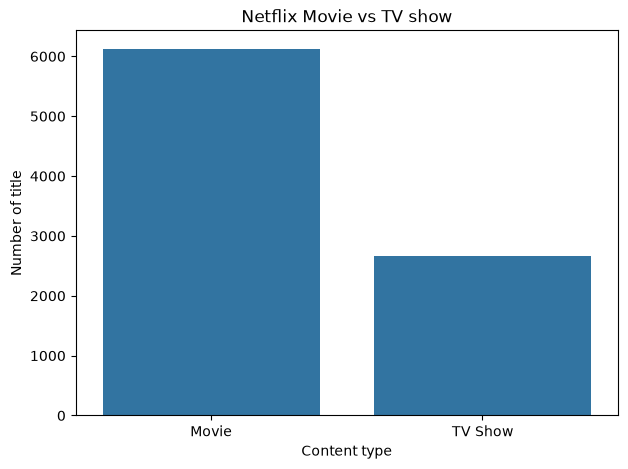

In [3]:
plt.figure(figsize=(7,5))
sns.countplot(data = ds,x = "type")
plt.title("Netflix Movie vs TV show")
plt.xlabel("Content type")
plt.ylabel("Number of title")
plt.show()

Feature adding

In [4]:
ds["features"]= (ds["type"]+"  "
    + ds["director"]+"  "
    + ds["country"]
    + ds["listed_in"]
    + ds["rating"]
    + ds["duration"])

print(ds[["title", "features"]].head())

                              title  \
0              Dick Johnson Is Dead   
1                         Ganglands   
2                     Midnight Mass   
3  Confessions of an Invisible Girl   
4                           Sankofa   

                                            features  
0  Movie  Kirsten Johnson  United StatesDocumenta...  
1  TV Show  Julien Leclercq  FranceCrime TV Shows...  
2  TV Show  Mike Flanagan  United StatesTV Dramas...  
3  Movie  Bruno Garotti  BrazilChildren & Family ...  
4  Movie  Haile Gerima  United StatesDramas, Inde...  


TF - IDF vectorization

In [5]:
tfidf = TfidfVectorizer(
    stop_words= "english",
    max_features=5000
)
tfidf_matrix = tfidf.fit_transform(ds["features"])
print("TF - IDF Matrix shape:", tfidf_matrix.shape)

TF - IDF Matrix shape: (8790, 5000)


Build recommandation system

In [6]:
def recommend(title, top_n=5):

    matches = ds.index[
        ds["title"].str.lower().str.strip()
        == title.lower().strip()
    ].tolist()

    if not matches:
        print("Movie or TV Show not found!")
        return pd.DataFrame()

    idx = matches[0]

    similarity_scores = cosine_similarity(
        tfidf_matrix[idx],
        tfidf_matrix
    ).flatten()

    similarity_scores[idx] = -1

    top_indices = similarity_scores.argsort()[-top_n:][::-1]

    recommendations = ds.iloc[top_indices][
        ["title", "type", "listed_in"]
    ].copy()

    recommendations["similarity_score"] = (
        similarity_scores[top_indices].round(3)
    )

    return recommendations

In [7]:
recommend("Stranger Things")

,title,type,listed_in,similarity_score
6613,Manifest,TV Show,"TV Dramas, TV Mysteries, TV Sci-Fi & Fantasy",0.925
8485,Helix,TV Show,"TV Horror, TV Mysteries, TV Sci-Fi & Fantasy",0.858
7446,Nightflyers,TV Show,"TV Horror, TV Mysteries, TV Sci-Fi & Fantasy",0.858
6923,Chilling Adventures of Sabrina,TV Show,"TV Horror, TV Mysteries, TV Sci-Fi & Fantasy",0.836
6639,Charmed,TV Show,"TV Dramas, TV Sci-Fi & Fantasy",0.807


In [8]:
recommend("The Crown")

,title,type,listed_in,similarity_score
8076,Man Down,TV Show,"British TV Shows, International TV Shows, TV C...",0.936
7272,The Last Kingdom,TV Show,"British TV Shows, International TV Shows, TV A...",0.850
7745,Traitors,TV Show,"British TV Shows, International TV Shows, TV D...",0.811
6867,Behind Her Eyes,TV Show,"British TV Shows, International TV Shows, TV D...",0.811
7799,Black Earth Rising,TV Show,"British TV Shows, International TV Shows, TV D...",0.811


In [9]:
def evaluate_recommendations(title):

    matches = ds.index[
        ds["title"].str.lower().str.strip()
        == title.lower().strip()
    ].tolist()

    if not matches:
        print("Title not found!")
        return

    original_genres = set(
        genre.strip()
        for genre in ds.loc[matches[0], "listed_in"].split(",")
        if genre.strip()
    )

    results = recommend(title)

    if results.empty:
        return

    overlaps = []

    for genres in results["listed_in"]:
        recommended_genres = set(
            genre.strip()
            for genre in genres.split(",")
            if genre.strip()
        )

        overlaps.append(
            len(original_genres & recommended_genres) > 0
        )

    print("Average Similarity Score:",
          round(results["similarity_score"].mean(), 3))

    print("Genre Overlap Rate:",
          round(np.mean(overlaps) * 100, 2), "%")

    display(results)

evaluate_recommendations("Stranger Things")

Average Similarity Score: 0.857
Genre Overlap Rate: 100.0 %


,title,type,listed_in,similarity_score
6613,Manifest,TV Show,"TV Dramas, TV Mysteries, TV Sci-Fi & Fantasy",0.925
8485,Helix,TV Show,"TV Horror, TV Mysteries, TV Sci-Fi & Fantasy",0.858
7446,Nightflyers,TV Show,"TV Horror, TV Mysteries, TV Sci-Fi & Fantasy",0.858
6923,Chilling Adventures of Sabrina,TV Show,"TV Horror, TV Mysteries, TV Sci-Fi & Fantasy",0.836
6639,Charmed,TV Show,"TV Dramas, TV Sci-Fi & Fantasy",0.807


In [10]:
movie_name = input("Enter Movie or TV Show Name: ")

results = recommend(movie_name)

if not results.empty:
    print("\nTop 5 Recommended Titles:")
    display(results)


Top 5 Recommended Titles:


,title,type,listed_in,similarity_score
7446,Nightflyers,TV Show,"TV Horror, TV Mysteries, TV Sci-Fi & Fantasy",1.000
7186,Warrior Nun,TV Show,"TV Action & Adventure, TV Mysteries, TV Sci-Fi...",0.866
7633,Stranger Things,TV Show,"TV Horror, TV Mysteries, TV Sci-Fi & Fantasy",0.858
8728,The Messengers,TV Show,"TV Dramas, TV Mysteries, TV Sci-Fi & Fantasy",0.855
6923,Chilling Adventures of Sabrina,TV Show,"TV Horror, TV Mysteries, TV Sci-Fi & Fantasy",0.853


In [11]:
results = recommend("Stranger Things")

results.to_csv(
    "netflix_recommendations.csv",
    index=False
)

print("Recommendations saved successfully!")

Recommendations saved successfully!
